# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/3StepFriday.csv',
        ),
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'], keep = 'last')
data['problem_type'] = numpy.select([data.problem_spc_tags.str.contains('FOF'), data.problem_spc_tags.str.contains('CNF')], ['FOF', 'CNF'], default = None)

good_problems = data.groupby('problem').strategy.nunique().loc[lambda x: x == x.max()].index
data = data[data.problem.isin(good_problems)]

renamer = {
    'LeanCoP': 'PyLeanCoP',
    'SATCoP_0': 'PySATCoP_0',
    'SATCoP': 'PySATCoP',
}
strategies = ['PyCoP', 'PyLeanCoP', 'PySATCoP_0', 'PySATCoP', 'SATResetCoP']

data = data.replace({'strategy': renamer})
data = data.sort_values(by = 'strategy', key = lambda x: x.map(strategies.index))

assert data.groupby('problem').strategy.count().nunique() == 1
assert data.groupby('strategy').problem.count().nunique() == 1
assert not data.problem_type.isnull().any()

In [5]:
data.strategy.value_counts()

strategy
PyCoP          16594
PyLeanCoP      16594
PySATCoP_0     16594
PySATCoP       16594
SATResetCoP    16594
Name: count, dtype: int64

In [6]:
data.head()

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
20,AGT011+1.p,PyCoP,timeout,NaN,False,4941.0,120007.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
15,AGT008+2.p,PyCoP,timeout,NaN,False,5597.0,120028.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
10,AGT006+1.p,PyCoP,timeout,NaN,False,4946.0,120027.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
82935,TOP042+2.p,PyCoP,timeout,NaN,False,239.0,121228.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
35,AGT018+2.p,PyCoP,timeout,NaN,False,4894.0,120012.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF


In [7]:
data.groupby('strategy').problem.nunique().sort_values()

strategy
PyCoP          16594
PyLeanCoP      16594
PySATCoP       16594
PySATCoP_0     16594
SATResetCoP    16594
Name: problem, dtype: int64

In [8]:
data.groupby('strategy').steps.max()

strategy
PyCoP          1000000.0
PyLeanCoP      1000000.0
PySATCoP       1000000.0
PySATCoP_0     1000000.0
SATResetCoP    1000000.0
Name: steps, dtype: float64

In [9]:
problems = data.problem.str[:3].value_counts().sort_index()
pandas.concat(
    [
        problems[0::3].reset_index(),
        problems[1::3].reset_index(),
        problems[2::3].reset_index(),
    ],
    axis = 1,
).fillna('')

,problem,count,problem,count,problem,count
0,AGT,270,ALG,2315,ANA,480.0
1,BIO,30,BOO,750,CAT,670.0
2,COL,1260,COM,375,CSR,4770.0
3,FLD,1405,GEG,5,GEO,4480.0
4,GRA,170,GRP,5330,HAL,50.0
5,HEN,340,HWC,30,HWV,1475.0
6,ITP,500,KLE,1270,KRS,1490.0
7,LAT,3790,LCL,4610,LDA,250.0
8,MED,60,MGT,790,MSC,125.0
9,MVA,75,NLP,2810,NUM,5315.0


# Analysing

In [10]:
control = ['FirstAction', 'LeanCopCut']

In [11]:
data.groupby('strategy').problem.count()

strategy
PyCoP          16594
PyLeanCoP      16594
PySATCoP       16594
PySATCoP_0     16594
SATResetCoP    16594
Name: problem, dtype: int64

In [12]:
pandas.crosstab(
    data.strategy,
    data.result,
    margins = True,
).sort_values('All')

result,Non-Theorem: no positive start clauses,Theorem,Theorem (SAT),All
strategy,,,,
PyCoP,46,795,0,841
PySATCoP_0,2,0,1871,1873
PyLeanCoP,2,1923,0,1925
PySATCoP,2,0,2509,2511
SATResetCoP,2,0,2971,2973
All,54,2718,7351,10123


In [13]:
data[data.problem == 'PUZ053-1.p']

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
46795,PUZ053-1.p,PyCoP,timeout,NaN,False,2541.0,120078.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,NaN,NaN,CNF
46796,PUZ053-1.p,PyLeanCoP,timeout,NaN,False,9616.0,120006.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,NaN,NaN,CNF
46797,PUZ053-1.p,PySATCoP_0,timeout,NaN,False,5181.0,120008.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,NaN,NaN,CNF
46798,PUZ053-1.p,PySATCoP,timeout,NaN,False,6574.0,120004.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,"literal=choices:6574,forward:64245,unique:466,...",NaN,CNF
46799,PUZ053-1.p,SATResetCoP,timeout,NaN,False,6752.0,120012.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,"literal=choices:6752,forward:124162,unique:818...",NaN,CNF


In [14]:
pandas.crosstab(
    data.result.fillna('?'),
    data.problem_declared_status,
)

problem_declared_status,ContradictoryAxioms,CounterSatisfiable,Open,Satisfiable,Theorem,Unknown,Unsatisfiable
result,,,,,,,
?,2533,3715,160,7229,28453,4420,26337
Non-Theorem: no positive start clauses,0,15,0,36,1,0,2
Theorem,23,0,0,0,1708,0,987
Theorem (SAT),89,0,0,0,3973,0,3289


In [15]:
data[data.solved]

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
300,ALG028+1.p,PyCoP,solved,Theorem,True,37.0,311.0,FOF_THM_RFO_PEQ,False,Theorem,unsat,NaN,NaN,FOF
61010,SEU158+1.p,PyCoP,solved,Theorem,True,13.0,1.0,FOF_THM_RFO_NEQ,False,Theorem,unsat,NaN,NaN,FOF
340,ALG067+1.p,PyCoP,solved,Theorem,True,116.0,478.0,FOF_THM_RFO_PEQ,False,Theorem,unsat,NaN,NaN,FOF
61025,SEU163+1.p,PyCoP,solved,Theorem,True,3.0,0.0,FOF_THM_RFO_NEQ,False,Theorem,unsat,NaN,NaN,FOF
82700,TOP002-2.p,PyCoP,solved,Theorem,True,3.0,0.0,CNF_UNS_RFO_NEQ_NHN,False,Unsatisfiable,unsat,NaN,NaN,CNF
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82874,TOP026+1.p,SATResetCoP,solved,Theorem (SAT),True,2088.0,5397.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:2088,forward:74498,unique:216,...",NaN,FOF
49684,RNG124+1.p,SATResetCoP,solved,Theorem (SAT),True,206.0,463.0,FOF_CAX_RFO_SEQ,False,ContradictoryAxioms,unsat,"literal=choices:206,forward:10397,unique:22,ti...",NaN,FOF
89,AGT016+2.p,SATResetCoP,solved,Theorem (SAT),True,993.0,4560.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:993,forward:206813,unique:64,t...",NaN,FOF
64,AGT004+1.p,SATResetCoP,solved,Theorem (SAT),True,1581.0,5922.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:1581,forward:205920,unique:87,...",NaN,FOF


In [16]:
data[data.problem_spc_tags.str.contains('FOF')].problem.str[6].value_counts()

problem
+    43895
Name: count, dtype: int64

In [17]:
data[data.solved].groupby('strategy').size()

strategy
PyCoP           795
PyLeanCoP      1923
PySATCoP       2509
PySATCoP_0     1871
SATResetCoP    2971
dtype: int64

# Results

<Axes: xlabel='strategy'>

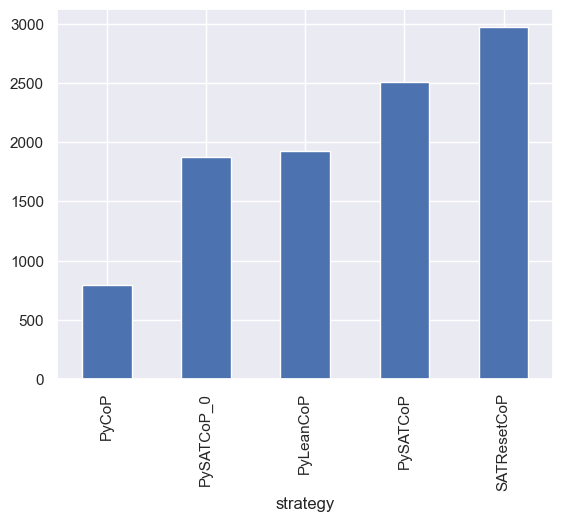

In [18]:
data[data.solved].strategy.value_counts(ascending = True).plot.bar()

In [19]:
data.groupby(['strategy', 'problem_type']).solved.sum().unstack()

problem_type,CNF,FOF
strategy,,
PyCoP,208,587
PyLeanCoP,723,1200
PySATCoP,1067,1442
PySATCoP_0,804,1067
SATResetCoP,1273,1698


In [20]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
).sort_values(by = ['strategy_left', 'strategy_right'], key = lambda x: x.map(strategies.index))

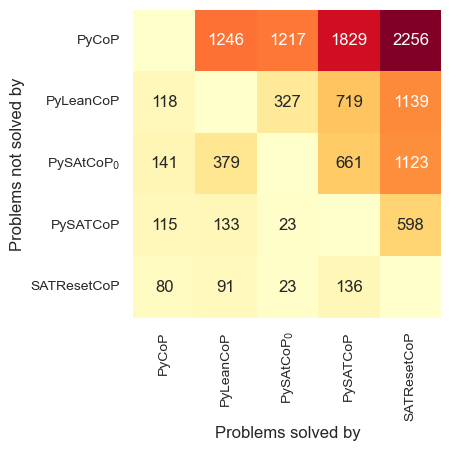

In [21]:
pyplot.rcParams['figure.figsize'] = (4, 4)
values = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts(sort = False)
    # .sort_index(key = lambda x: x.map(strategies.index))
)

results = (
    values
    .unstack(level = 'strategy_right', fill_value = 0)
    .sort_index(axis = 0, key = lambda x: x.map(strategies.index))
    .sort_index(axis = 1, key = lambda x: x.map(strategies.index))
)

plot = (
    results.
    rename_axis(index = 'Problems not solved by', columns = 'Problems solved by').
    rename(index = {'PySATCoP_0': 'PySAtCoP$_0$'}).
    rename(columns = {'PySATCoP_0': 'PySAtCoP$_0$'})
)

seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(results.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'YlOrRd',
    square = True,
    cbar = False,
)

pyplot.gca().tick_params(axis = 'both', labelsize = 'small')
pyplot.savefig('Vampire/figures/solved_heatmap.png', bbox_inches = 'tight', dpi = 400)

# 

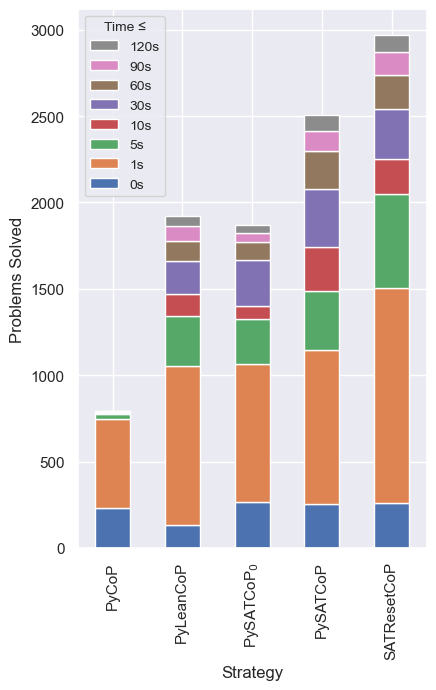

In [22]:
pyplot.rcParams["figure.figsize"] = (4.5, 7)

times = [0, 1, 5, 10, 30, 60, 90, 120]
solved_time = Series(
    numpy.select(
        [data.solved & (data.time_ms <= 1000 * x) for x in times],
        [x for x in times],
        default = None,
    ),
    index = data.index,
    name = 'solved_time',
)

q = pandas.concat([data, solved_time], axis = 1)[['strategy', 'solved_time']]
b = q.groupby('strategy').value_counts(sort = False).sort_index(level = [0, 1]).unstack().sort_index(key = lambda x: x.map(strategies.index))
b.index = b.index.str.replace('_0', '$_0$')
b.columns = [f'{x}s' for x in b.columns]
b.plot.bar(stacked = True)
pyplot.ylabel('Problems Solved')
pyplot.xlabel('Strategy')
pyplot.legend(loc = 2, fontsize = 'small', reverse = True, title = 'Time ≤', title_fontsize = 'small')

pyplot.savefig('Vampire/figures/strategy_solved_time_plot.png', dpi = 400, bbox_inches = 'tight')

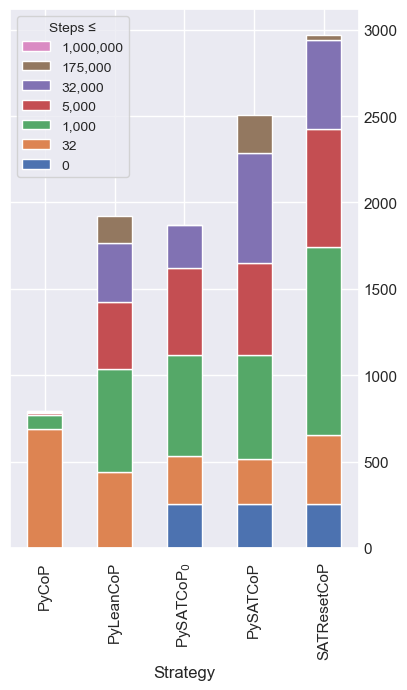

In [23]:
times = [0, 32, 1000, 5000, 32000, 175000, 1000000]
solved_time = Series(
    numpy.select(
        [data.solved & (data.steps <= x) for x in times],
        [x for x in times],
        default = None,
    ),
    index = data.index,
    name = 'solved_time',
)

q = pandas.concat([data, solved_time], axis = 1)[['strategy', 'solved_time']]
b = q.groupby('strategy').value_counts(sort = False).sort_index(level = [0, 1]).unstack().sort_index(key = lambda x: x.map(strategies.index))
b.columns = [f'{x:,d}' for x in b.columns]
b.index = b.index.str.replace('_0', '$_0$')
b.plot.bar(stacked = True)
# pyplot.ylabel('Problems Solved')
pyplot.xlabel('Strategy')
pyplot.legend(loc = 0, fontsize = 'small', reverse = True, title = 'Steps ≤', title_fontsize = 'small')
pyplot.gca().yaxis.tick_right()
pyplot.gca().tick_params(axis = 'y', length = 0)

pyplot.savefig('Vampire/figures/strategy_solved_steps_plot.png', dpi = 400, bbox_inches = 'tight')

In [24]:
b.index = b.index.str.replace('Py', 'As')
b

,0,32,"1,000","5,000","32,000","175,000","1,000,000"
strategy,,,,,,,
AsCoP,NaN,689.0,81.0,13.0,7.0,3.0,2.0
AsLeanCoP,NaN,439.0,599.0,384.0,344.0,157.0,NaN
AsSATCoP$_0$,254.0,276.0,587.0,506.0,245.0,3.0,NaN
AsSATCoP,254.0,262.0,602.0,534.0,636.0,221.0,NaN
SATResetCoP,255.0,401.0,1085.0,683.0,516.0,31.0,NaN


In [25]:
b

,0,32,"1,000","5,000","32,000","175,000","1,000,000"
strategy,,,,,,,
AsCoP,NaN,689.0,81.0,13.0,7.0,3.0,2.0
AsLeanCoP,NaN,439.0,599.0,384.0,344.0,157.0,NaN
AsSATCoP$_0$,254.0,276.0,587.0,506.0,245.0,3.0,NaN
AsSATCoP,254.0,262.0,602.0,534.0,636.0,221.0,NaN
SATResetCoP,255.0,401.0,1085.0,683.0,516.0,31.0,NaN


In [26]:
merged.strategy_right.unique()

array(['PyCoP', 'PyLeanCoP', 'PySATCoP_0', 'PySATCoP', 'SATResetCoP'],
      dtype=object)

In [27]:
merged[(merged.strategy_left == 'SATSolveLiteral') & (merged.strategy_right == 'SATResetAtStaleAction') & merged.solved_right & merged.solved_left][['problem', 'steps_left', 'steps_right']]

,problem,steps_left,steps_right


In [28]:
merged.columns

Index(['problem', 'strategy_left', 'status_left', 'result_left', 'solved_left',
       'steps_left', 'time_ms_left', 'problem_spc_tags_left',
       'problem_typed_left', 'problem_declared_status_left',
       'problem_declared_status_kind_left', 'info_left', 'error_left',
       'problem_type_left', 'strategy_right', 'status_right', 'result_right',
       'solved_right', 'steps_right', 'time_ms_right',
       'problem_spc_tags_right', 'problem_typed_right',
       'problem_declared_status_right', 'problem_declared_status_kind_right',
       'info_right', 'error_right', 'problem_type_right'],
      dtype='object')

In [29]:
merged[
    (merged.strategy_left == 'FirstAction') &
    (merged.strategy_right == 'SATSolve') &
    merged.solved_right &
    merged.solved_left &
    (merged.steps_right == 0) &
    (merged.steps_left < 10000)
    ][['problem', 'time_ms_left', 'steps_left', 'time_ms_right', 'steps_right']].sort_values('steps_left', ascending = False)

,problem,time_ms_left,steps_left,time_ms_right,steps_right


In [30]:
data.head()

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
20,AGT011+1.p,PyCoP,timeout,NaN,False,4941.0,120007.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
15,AGT008+2.p,PyCoP,timeout,NaN,False,5597.0,120028.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
10,AGT006+1.p,PyCoP,timeout,NaN,False,4946.0,120027.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
82935,TOP042+2.p,PyCoP,timeout,NaN,False,239.0,121228.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF
35,AGT018+2.p,PyCoP,timeout,NaN,False,4894.0,120012.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN,FOF


In [31]:
pandas.concat(
    [
        data[data.solved & (data.problem_type == 'CNF')].groupby('problem').first().strategy.value_counts().rename('CNF'),
        data[data.solved & (data.problem_type == 'FOF')].groupby('problem').first().strategy.value_counts().rename('FOF'),
    ],
    axis = 1,
)

,CNF,FOF
strategy,,
PyLeanCoP,523,723
SATResetCoP,224,254
PySATCoP,208,194
PyCoP,208,587
PySATCoP_0,178,129


## Violinplots

<Axes: xlabel='time_ms', ylabel='problem'>

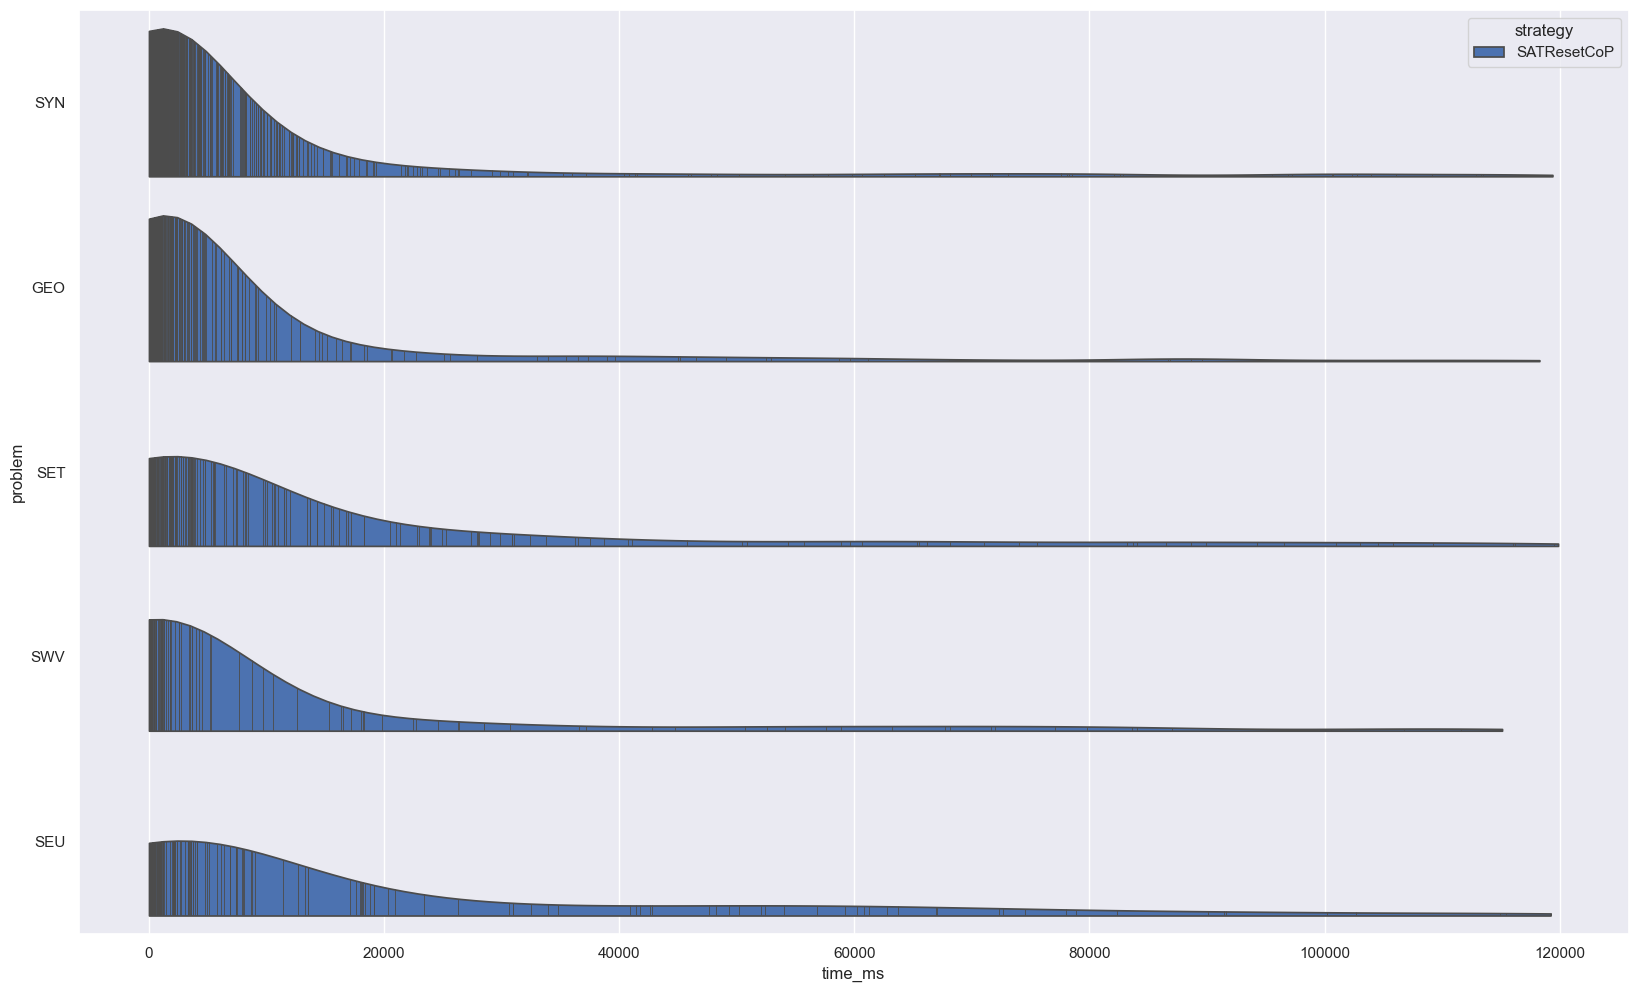

In [32]:
pyplot.rcParams["figure.figsize"] = (20, 12)
categories = data[data.solved & (data.strategy == 'SATResetCoP')].problem.str[:3].value_counts()[:5].index
down = data[data.solved & data.strategy.isin(['SATCoP', 'SATResetCoP']) & data.problem.str[:3].isin(categories)].copy()
seaborn.violinplot(
    down,
    x = 'time_ms',
    y = down.problem.str[:3],
    order = categories,
    hue = down.strategy,
    fill = True,
    inner = 'stick',
    split = True,
    cut = 0,
    saturation = 1,
)

In [33]:
down.problem.value_counts().value_counts()

count
1    1637
Name: count, dtype: int64

In [34]:
down.loc[lambda x: x.time_ms < 90000].sort_values('time_ms', ascending = False)

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
52149,SET011+3.p,SATResetCoP,solved,Theorem (SAT),True,26845.0,89884.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"score=1.0; literal=choices:26845,forward:32158...",NaN,FOF
16329,GEO195+3.p,SATResetCoP,solved,Theorem (SAT),True,31572.0,89567.0,FOF_THM_RFO_NEQ,False,Theorem,unsat,"score=1.0; literal=choices:31572,forward:46138...",NaN,FOF
55144,SET242-6.p,SATResetCoP,solved,Theorem (SAT),True,15169.0,88666.0,CNF_UNS_RFO_SEQ_NHN,False,Unsatisfiable,unsat,"score=1.0; literal=choices:15169,forward:32076...",NaN,CNF
16489,GEO260+1.p,SATResetCoP,solved,Theorem (SAT),True,34270.0,88620.0,FOF_THM_RFO_NEQ,False,Theorem,unsat,"score=1.0; literal=choices:34270,forward:61554...",NaN,FOF
67374,SWV185+1.p,SATResetCoP,solved,Theorem (SAT),True,658.0,86990.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:658,forward:179147,unique:117,...",NaN,FOF
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67234,SWV045+1.p,SATResetCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetCoP,cuts:on,s:0,r:0,e:0,b...",NaN,FOF
67269,SWV080+1.p,SATResetCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetCoP,cuts:on,s:0,r:0,e:0,b...",NaN,FOF
67264,SWV075+1.p,SATResetCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetCoP,cuts:on,s:0,r:0,e:0,b...",NaN,FOF
67274,SWV085+1.p,SATResetCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetCoP,cuts:on,s:0,r:0,e:0,b...",NaN,FOF


In [35]:
data.strategy.value_counts()

strategy
PyCoP          16594
PyLeanCoP      16594
PySATCoP_0     16594
PySATCoP       16594
SATResetCoP    16594
Name: count, dtype: int64

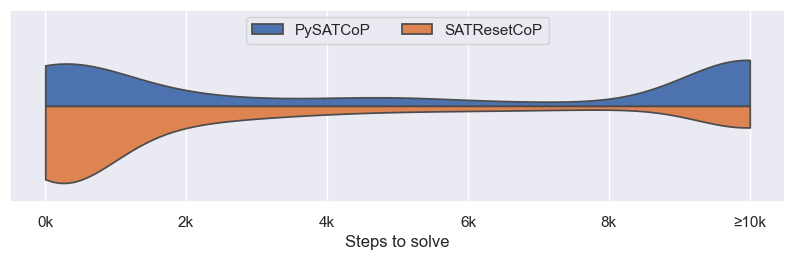

In [36]:
from matplotlib.ticker import FuncFormatter

pyplot.rcParams["figure.figsize"] = (10, 2.5)
lim = 10000

down = data[data.strategy.isin(['PySATCoP', 'SATResetCoP'])].groupby('problem').filter(lambda x: x.solved.any()).copy()
down.loc[~down.solved | (down.steps > lim), 'steps'] = lim
down.loc[:, 'dummy'] = 'SWV'

seaborn.violinplot(
    down,
    x = 'steps',
    hue = down.strategy,
    fill = True,
    inner = None,
    split = True,
    cut = 0,
    saturation = 1,
    density_norm = 'area',
    common_norm = True,
    legend = True,
)

# pyplot.ylabel('All TPTP Problems')
pyplot.xlabel('Steps to Solve')

pyplot.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: (f'≥' if x == lim else '') +  f'{int(x // 1000)}k'))
pyplot.gca().set_xlabel('Steps to solve')
pyplot.gca().get_yticklabels()[0].set_color('white')
pyplot.gca().yaxis.label.set_fontweight('bold')

pyplot.legend(title = '', ncols = 2, loc = 9)

pyplot.savefig('Vampire/figures/violinplot_all_problems.png', dpi = 300, bbox_inches = 'tight')

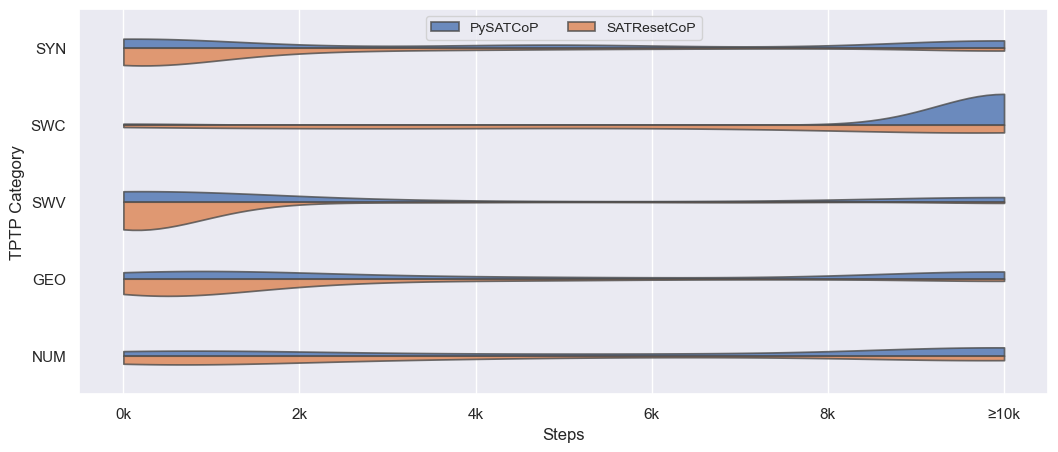

In [59]:
from matplotlib.ticker import FuncFormatter

ratio = 2
pyplot.rcParams["figure.figsize"] = (25 / ratio, 10 / ratio)

lim = 10000
cats = ['SYN', 'SWC', 'SWV', 'GEO', 'NUM']

down = data[data.strategy.isin(['PySATCoP', 'SATResetCoP'])].groupby('problem').filter(lambda x: x.solved.any()).copy()
down.loc[:, 'category'] = down.problem.str[:3]
down.loc[~down.solved | (down.steps > lim), 'steps'] = lim

seaborn.violinplot(
    down,
    y = 'category',
    x = 'steps',
    order = cats,
    hue = down.strategy,
    fill = True,
    inner = None,
    split = True,
    cut = 0,
    saturation = 1,
    density_norm = 'area',
    common_norm = True,
    alpha = .8,
    # legend = False,
)

pyplot.ylabel('TPTP Category')
pyplot.xlabel('Steps')

pyplot.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: (f'≥' if x == lim else '') +  f'{int(x // 1000)}k'))
pyplot.legend(title = '', ncols = 2, loc = 9, fontsize = 'small')

pyplot.savefig('Vampire/figures/violinplots.png', dpi = 300, bbox_inches = 'tight')

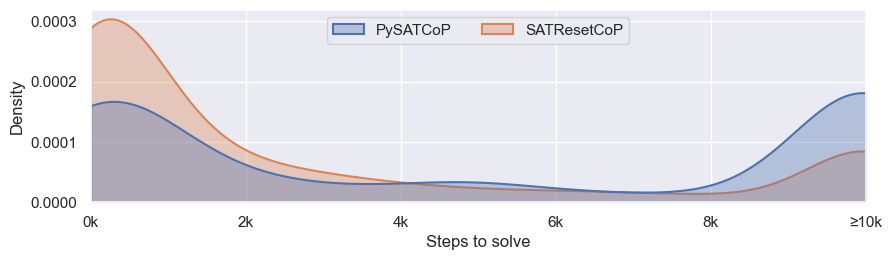

In [38]:
from matplotlib.ticker import FuncFormatter

pyplot.rcParams["figure.figsize"] = (10, 2.5)
lim = 10000

down = data[data.strategy.isin(['PySATCoP', 'SATResetCoP'])] \
  .groupby('problem') \
  .filter(lambda x: x.solved.any()) \
  .copy()

down.loc[~down.solved | (down.steps > lim), 'steps'] = lim

ax = seaborn.kdeplot(
  data=down,
  x='steps',
  hue='strategy',
  fill=True,
  common_norm=False,
  cut=0,
  alpha=0.35,
  linewidth=1.5,
)

ax.set_xlabel('Steps to solve')
ax.set_ylabel('Density')
ax.set_xlim(0, lim)

ax.xaxis.set_major_formatter(
  FuncFormatter(lambda x, _: (f'≥' if x == lim else '') + f'{int(x // 1000)}k')
)

seaborn.move_legend(ax, 'upper center', title='', ncols=2)

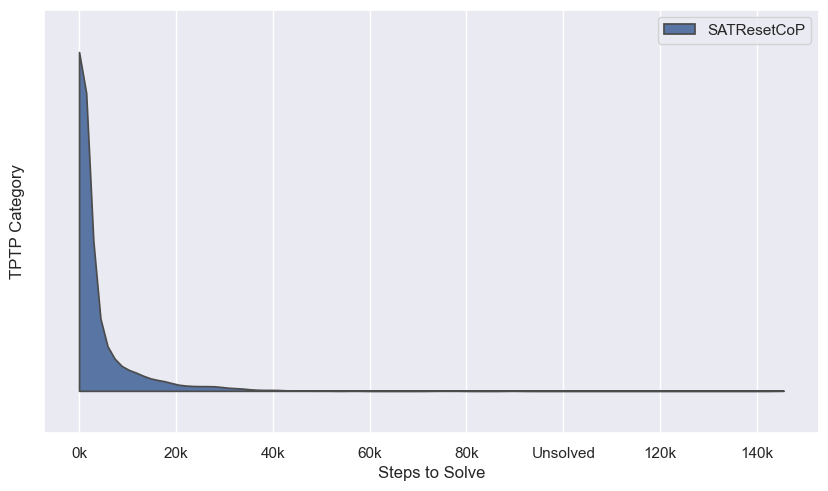

In [39]:
from matplotlib.ticker import FuncFormatter

pyplot.rcParams["figure.figsize"] = (10, 5.5)
down = data[data.strategy.isin(['SATCoP', 'SATResetCoP'])].groupby('problem').filter(lambda x: x.solved.any()).copy()
down.loc[~down.solved, 'steps'] = 100000
# down.loc[down.strategy == 'SATCoP_2', 'strategy'] = 'SATCoP'
# down = down[down.problem.str[:3].isin(['SYN', 'SYO', 'SET', """ 'SWV', 'ALG' """])]
seaborn.violinplot(
    down,
    x = 'steps',
    hue = down.strategy,
    # y = down.problem.str[:3],
    fill = True,
    inner = None,
    split = True,
    cut = 0,
    saturation = .75,
    density_norm = 'area',
    common_norm = True,
)

pyplot.ylabel('TPTP Category')
pyplot.xlabel('Steps to Solve')

pyplot.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: 'Unsolved' if x == 100000 else f'{int(x // 1000)}k'))
pyplot.legend(title = '', ncols = 2, loc = 0)

# pyplot.savefig('Paris_slides/figures/violinplot.png', bbox_inches = 'tight', dpi = 300)

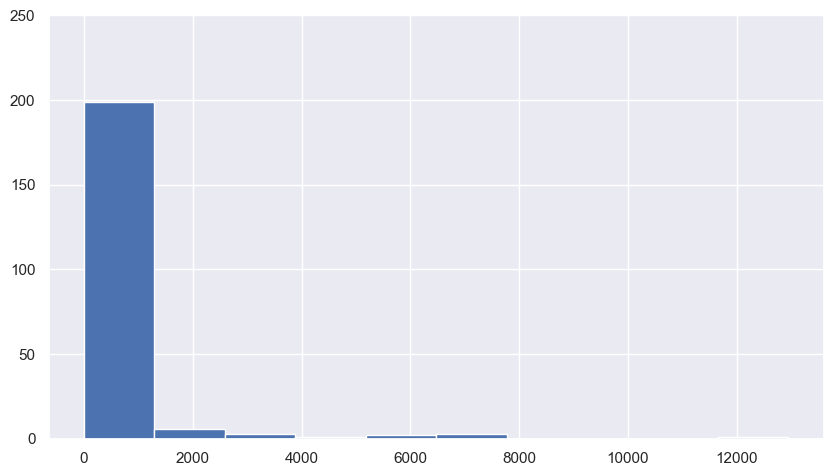

In [40]:
for k, v in down[down.problem.str[:3] == 'SWV'].groupby('strategy'):
    v.steps.hist()
    pyplot.ylim(0, 250)
    pyplot.show()

In [41]:
data.strategy.value_counts()

strategy
PyCoP          16594
PyLeanCoP      16594
PySATCoP_0     16594
PySATCoP       16594
SATResetCoP    16594
Name: count, dtype: int64

In [42]:
a = down
pandas.crosstab(
    a.strategy,
    a.solved,
)

solved,True
strategy,
SATResetCoP,2971


In [43]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

<Axes: xlabel='steps'>

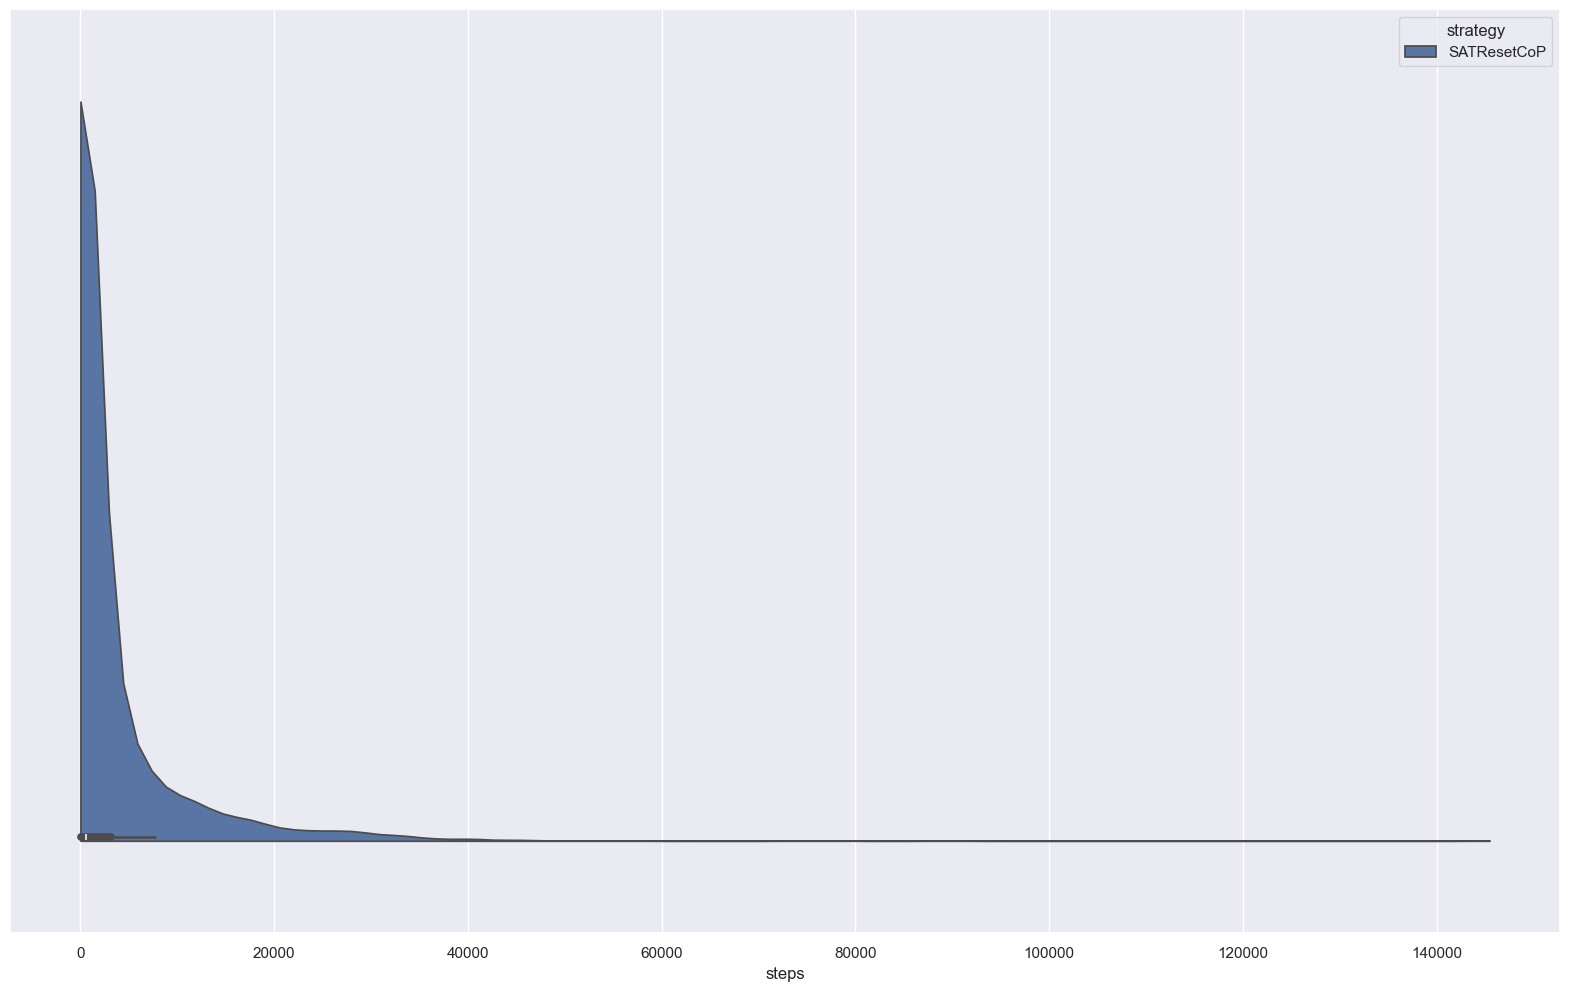

In [44]:
pyplot.rcParams["figure.figsize"] = (20, 12)
down = data[data.strategy.isin(['SATCoP', 'SATResetCoP'])].groupby('problem').filter(lambda x: x.solved.any()).copy()
down.loc[~down.solved, 'steps'] = 100000
seaborn.violinplot(
    down,
    x = 'steps',
    hue = down.strategy,
    fill = True,
    # inner = 'stick',
    split = True,
    cut = 0,
    # saturation = 1,
)

## Single Tree

In [45]:
(
    data
    .sort_values('problem')
    [data.strategy.isin(['SATCoP', 'SATResetCoP'])]
    .iloc[:10]
    .groupby('problem')
    .filter(lambda x: x.solved.all())
    .groupby('problem')
    .apply(lambda x: 0)
)

/tmp/ipykernel_809783/387359403.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data
/tmp/ipykernel_809783/387359403.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: 0)


problem
AGT001+1.p    0
AGT001+2.p    0
AGT002+1.p    0
AGT002+2.p    0
AGT003+1.p    0
AGT003+2.p    0
AGT004+1.p    0
AGT004+2.p    0
AGT005+2.p    0
dtype: int64

In [46]:
data.strategy.unique()

array(['PyCoP', 'PyLeanCoP', 'PySATCoP_0', 'PySATCoP', 'SATResetCoP'],
      dtype=object)

In [47]:
comp = merged[
    (merged.strategy_left == 'SATCoP_2') & (merged.strategy_right == 'SATResetCoP') & merged.solved_left & merged.solved_right
]
comp.loc[:, 'step_diff'] = comp.steps_right - comp.steps_left
best = (
    comp
    [(comp.steps_left < 300) & (comp.steps_right < 300)]
    .sort_values('step_diff')[['problem', 'steps_left', 'steps_right', 'step_diff']]
    .loc[lambda x: x.problem.str.contains('-') & x.problem.str.contains('SYN')]
    .head(20)
)
best

,problem,steps_left,steps_right,step_diff


In [48]:
' '.join(best.problem)

''

# Verification

In [49]:
verify = pandas.read_csv('results/SATReset10MinutesFull.csv')

In [50]:
verify

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error
0,AGT001+1.p,ResetSATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
1,AGT001+2.p,ResetSATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
2,AGT002+1.p,ResetSATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
3,AGT002+2.p,ResetSATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
4,AGT003+1.p,ResetSATCoP,solved,Theorem (SAT),True,18417.0,56508.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15635,TOP049-1.p,ResetSATCoP,max_steps,NaN,False,1000000.0,92607.0,CNF_UNS_RFO_PEQ_UEQ,False,Unsatisfiable,unsat,NaN,NaN
15636,TOP050-1.p,ResetSATCoP,max_steps,NaN,False,1000000.0,182305.0,CNF_UNS_RFO_PEQ_UEQ,False,Unsatisfiable,unsat,NaN,NaN
15637,TOP051-1.p,ResetSATCoP,max_steps,NaN,False,1000000.0,94688.0,CNF_UNS_RFO_PEQ_UEQ,False,Unsatisfiable,unsat,NaN,NaN
15638,TOP052-1.p,ResetSATCoP,timeout,NaN,False,840250.0,600001.0,CNF_UNS_RFO_PEQ_UEQ,False,Unsatisfiable,unsat,NaN,NaN


In [51]:
a = verify[verify.problem_spc_tags.str.contains('FOF')]
b = verify[verify.problem_spc_tags.str.contains('CNF')]

pandas.concat(
    [
        pandas.crosstab(a.problem_declared_status, a.solved),
        pandas.crosstab(b.problem_declared_status, b.solved),
    ],
    keys = ['FOF', 'CNF'],
    axis = 1,
).fillna(0).astype(int)

FOF         CNF      
solved                  False True  False True 
problem_declared_status                        
ContradictoryAxioms       204    39     0     0
CounterSatisfiable        732     0     0     0
Open                        4     0    28     0
Satisfiable               350     0  1094     0
Theorem                  4426  1823     0     0
Unknown                    94     0   745     0
Unsatisfiable             100    72  4496  1433

In [52]:
pandas.crosstab(
    a.problem_declared_status,
    a.solved,
)

solved,False,True
problem_declared_status,,
ContradictoryAxioms,204,39
CounterSatisfiable,732,0
Open,4,0
Satisfiable,350,0
Theorem,4426,1823
Unknown,94,0
Unsatisfiable,100,72
